# V0.1 LyoPronto Freezing Calculator

Enables an estimation of the freezing duration given a known heat transfer coefficient of the vial.

V0.1 - 21.07.2025 - HC (Erstellung des Programmes)

In [3]:
# Image
from IPython.display import Image
from IPython.core.display import HTML

image_paths = ["freezing_calculator_1.PNG", "freezing_calculator_2.PNG"]
html_code = '<div style="display: flex; gap: 10px;">'
for img_path in image_paths:
    html_code += f'<img src="{img_path}" style="height: 350px;">'
html_code += '</div>'

display(HTML(html_code))

## Loading libraries

In [5]:
# Libraries
import scipy.optimize as sp
import numpy as np
import pylab as plt
import pandas as pd
import math
import csv
import os
import time
from pdb import set_trace as keyboard

import functions_freezing as fn_ref
import constants_freezing as cn_ref
import freezing as ref
import functions_lyoPronto as fn_lyo
import freezing as freezing

## Input

In [7]:
# Input
version_name = 'V0.1'
customer_name =''

# Input temperature profile
temp_setpt = [20, -44, -44] # [deg C]
temp_time_setpt = [128/60, 110/60] # h

# Input prodcut specified temperatures

# Initial product temperature for freezing [degC]
Tpr0 = 20 # [deg C]

# Freezing temperature [deg C]
Tf = -1.54 # [deg C]

# Nucleation temperature [deg C]
Tn = -5.84 # [deg C]

# Process specific parameters
vialType = '5ml(Schott)' # Gesamte Liste folgt nach Verifizierung
fill_volume = 2 # [ml] 
ProductParameter = 1 # 1 - Manitol, 2 - Sucrose
  
# Heat transfer coefficient between product and surroundings
h_freezing = 80 #  in W/m^2/K

dt = 0.001 # [h]

In [8]:

#vial = fn_ref.VIAL(vialType, fill_volume)
product = fn_ref.productInput(ProductParameter, Tn, Tf, Tpr0)
vial = fn_ref.VIAL(vialType, fill_volume)
save_recipe = 'NO'
current_time = time.strftime("%y%m%d_%H%M",time.localtime())
#directory = f"LP_{version_name}_{customer_name}_{product['Name']}_{vial['Name']}_{vial['Vfill']}ml_N{vial['nVial']}_{current_time}"
#os.makedirs(directory)
#start_time = time.time()

## Freezing Calculator Tool

In [10]:
# Freezing Calculator

freezing_output_saved = freezing.freeze(vial, product, h_freezing, temp_setpt, temp_time_setpt, dt)


## Diagrams

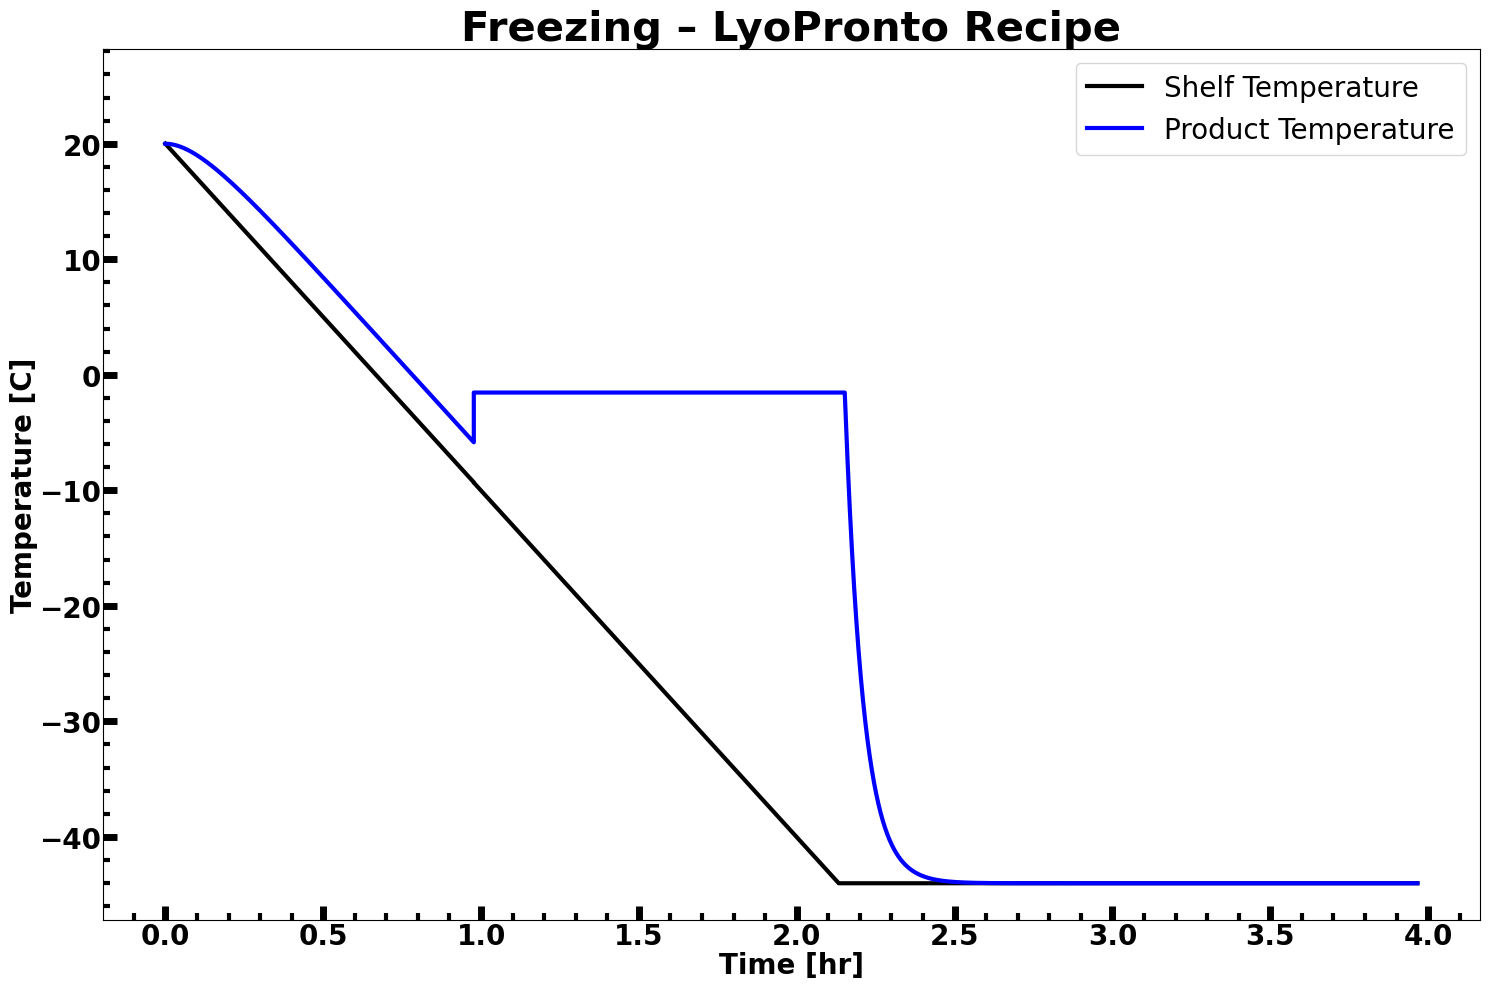

In [12]:
# Plotstyle

figwidth = 15
figheight = 10
lineWidth = 3
textFontSize = 30
gcafontSize = 20
markerSize = 10
labelPad = 1
majorTickWidth = 5
minorTickWidth = 3
majorTickLength = 10
minorTickLength = 5

Color_list = ['b','m','g','c','r','y','k']	# Line colors

# Diagrams
title="Freezing – LyoPronto Recipe"

fig = plt.figure(0, figsize=(figwidth, figheight))
ax = fig.add_subplot(1, 1, 1)
plt.axes(ax)
plt.minorticks_on()
plt.setp(ax.get_xticklabels(), fontsize=gcafontSize, fontweight='bold')
plt.setp(ax.get_yticklabels(), fontsize=gcafontSize, fontweight='bold')
ax.tick_params(axis='x', direction='in', pad=labelPad, width=majorTickWidth, length=majorTickLength, bottom=1, top=0)
ax.tick_params(axis='y', direction='in', pad=labelPad, width=majorTickWidth, length=majorTickLength, left=1, right=0)
ax.tick_params(axis='x', which='minor', direction='in', width=minorTickWidth, length=minorTickLength, bottom=1, top=0)
ax.tick_params(axis='y', which='minor', direction='in', width=minorTickWidth, length=minorTickLength, left=1, right=0)
ax.plot(freezing_output_saved[:, 0], freezing_output_saved[:, 1], '-k', linewidth=lineWidth, label="Shelf Temperature")
ax.plot(freezing_output_saved[:, 0], freezing_output_saved[:, 2], '-b', linewidth=lineWidth, label="Product Temperature")
ax.set_xlabel("Time [hr]", fontsize=gcafontSize, fontweight='bold')
ax.set_ylabel("Temperature [C]", fontsize=gcafontSize, fontweight='bold')
ax.xaxis.labelpad = labelPad
ax.yaxis.labelpad = labelPad
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles, labels, prop={'size': 20}, loc='best')
ll, ul = ax.get_ylim()
ax.set_ylim([ll, ul + 5.0])
plt.title(title, fontsize=textFontSize, fontweight='bold')
plt.tight_layout()

figure_name = 'Freezing_LyoPronto_Recipe_' + current_time + '.pdf'
plt.savefig(figure_name)

plt.show()  
plt.close()


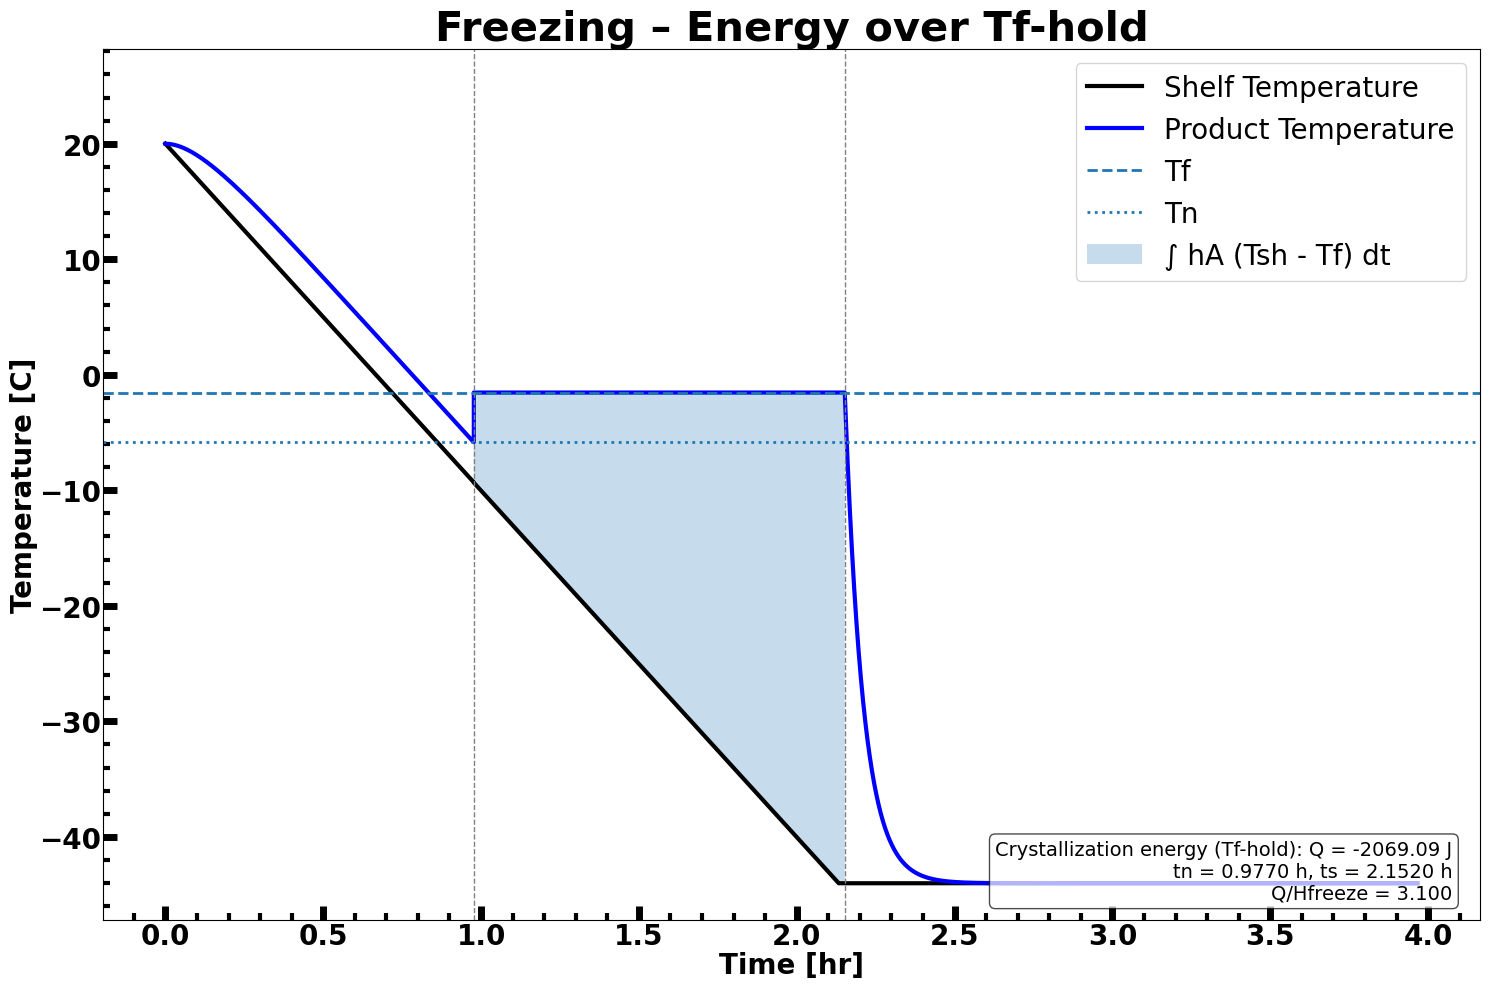

In [13]:
# Energy calculation

out = ref.freeze(vial, product, h_freezing, temp_setpt, temp_time_setpt, dt)

ref.plot_with_energy(out, vial, product, h_freezing, title="Freezing – Energy over Tf-hold")


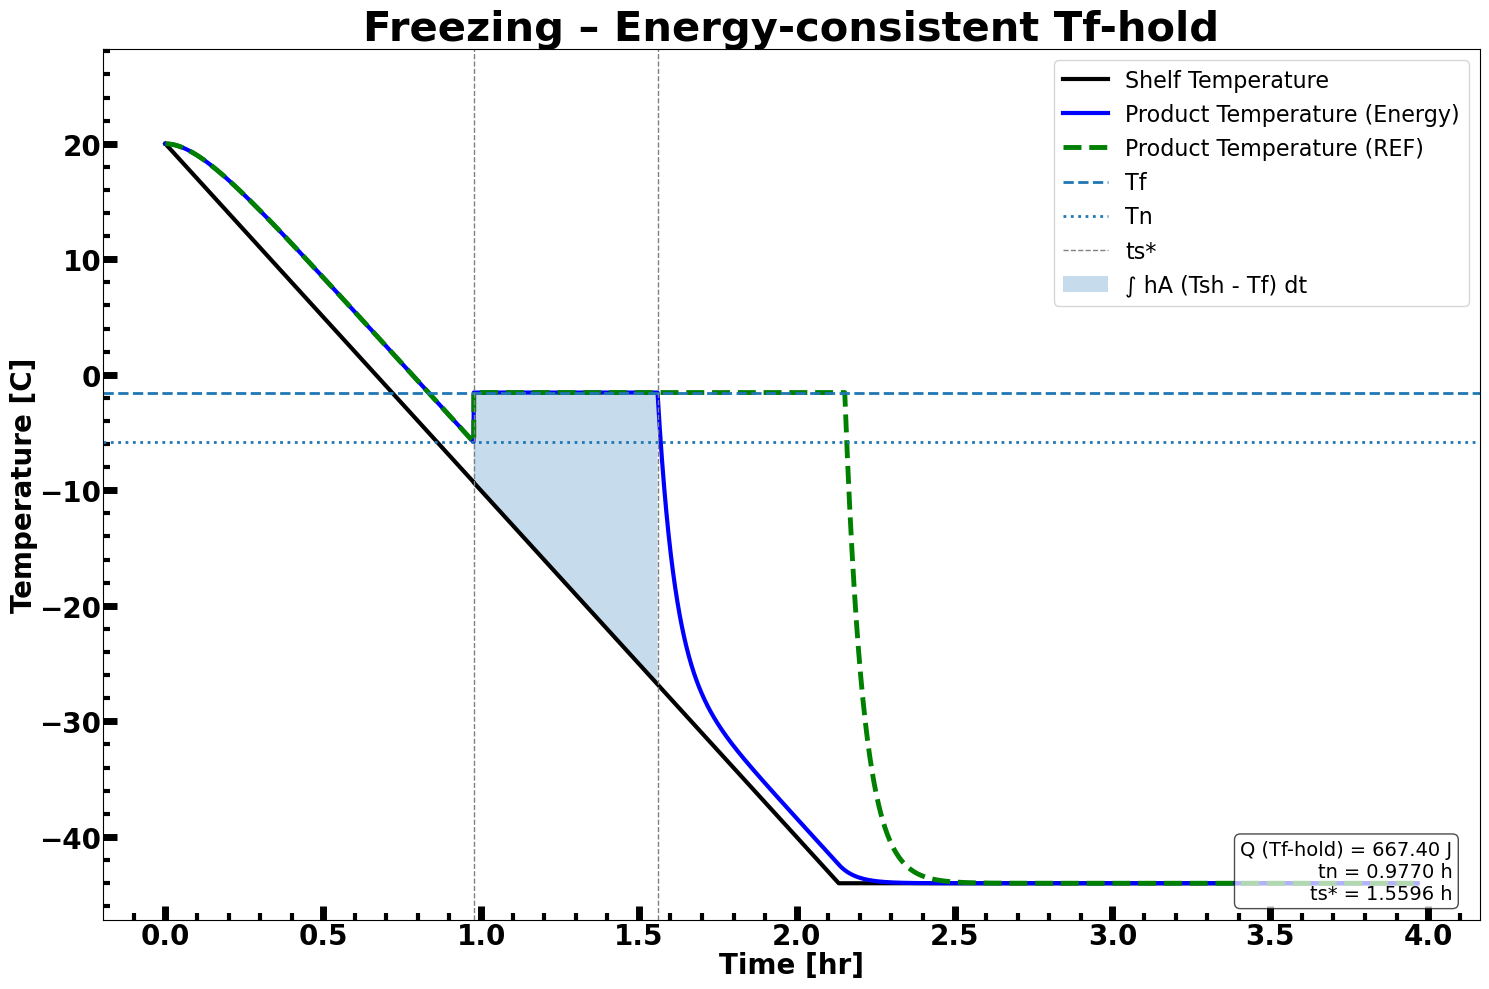

In [14]:
# Energy optimizer calculation

out_ref = ref.freeze(vial, product, h_freezing, temp_setpt, temp_time_setpt, dt)


tn, ts_star, Q_at_ts, Q_lat, reached = ref.backsolve_ts_star(out_ref, vial, product, h_freezing, rho_solution=1000.0, L_f=333_700.0)

out_new = ref.build_energy_consistent(out_ref, vial, product, h_freezing, tn, ts_star)


ref.plot_ref_vs_energy(out_ref, out_new, product, tn, ts_star, Q_at_ts)


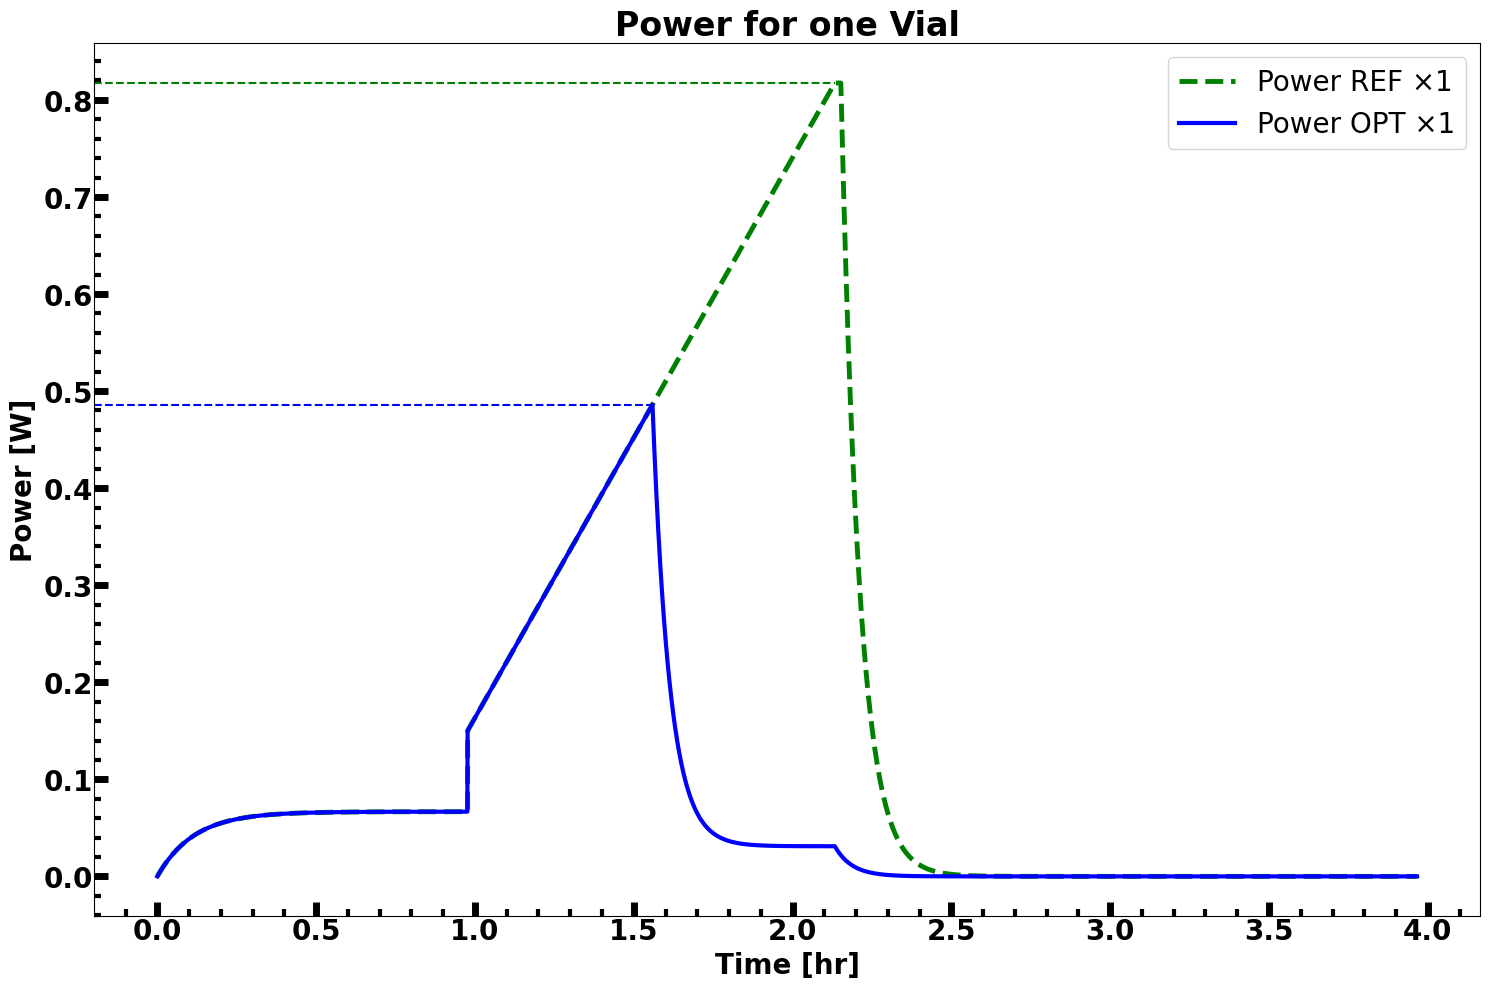

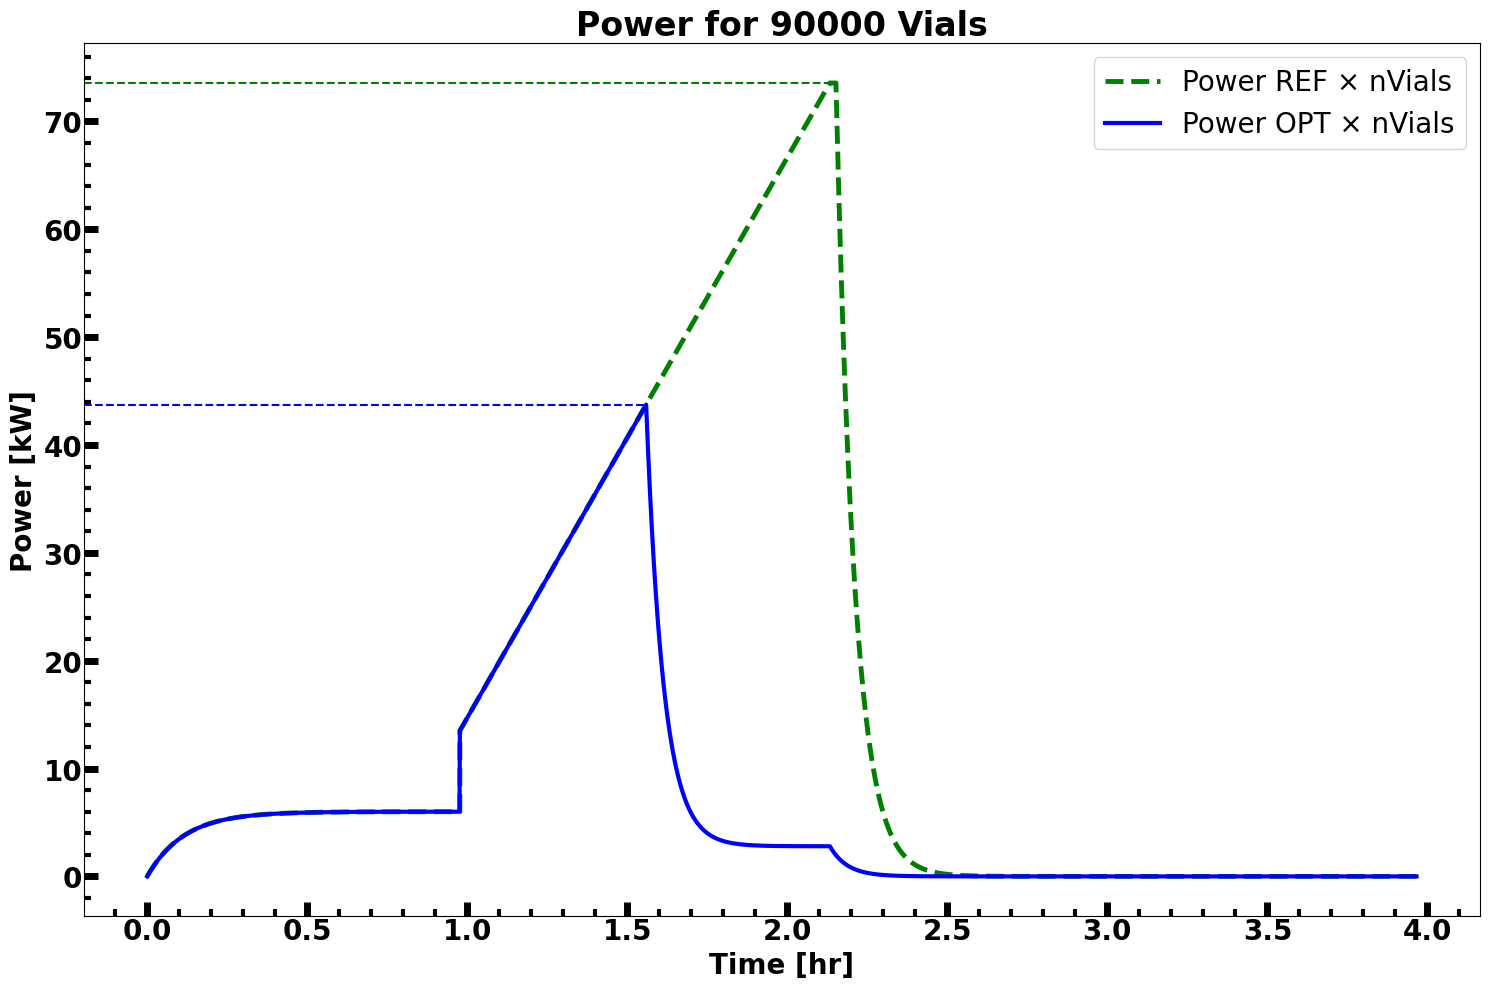

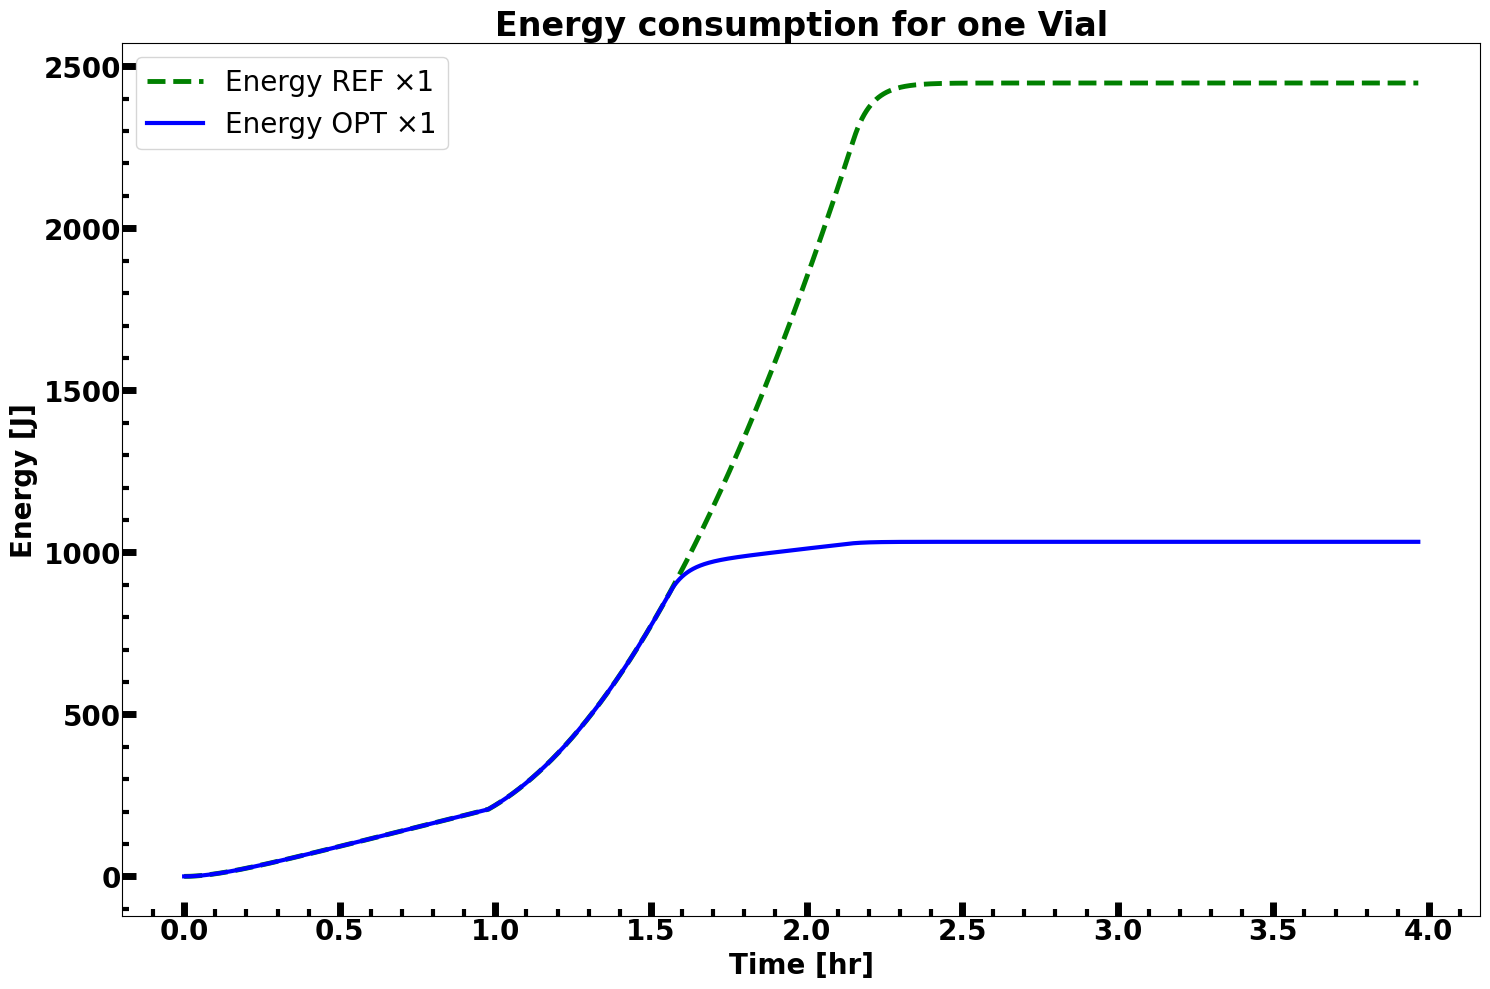

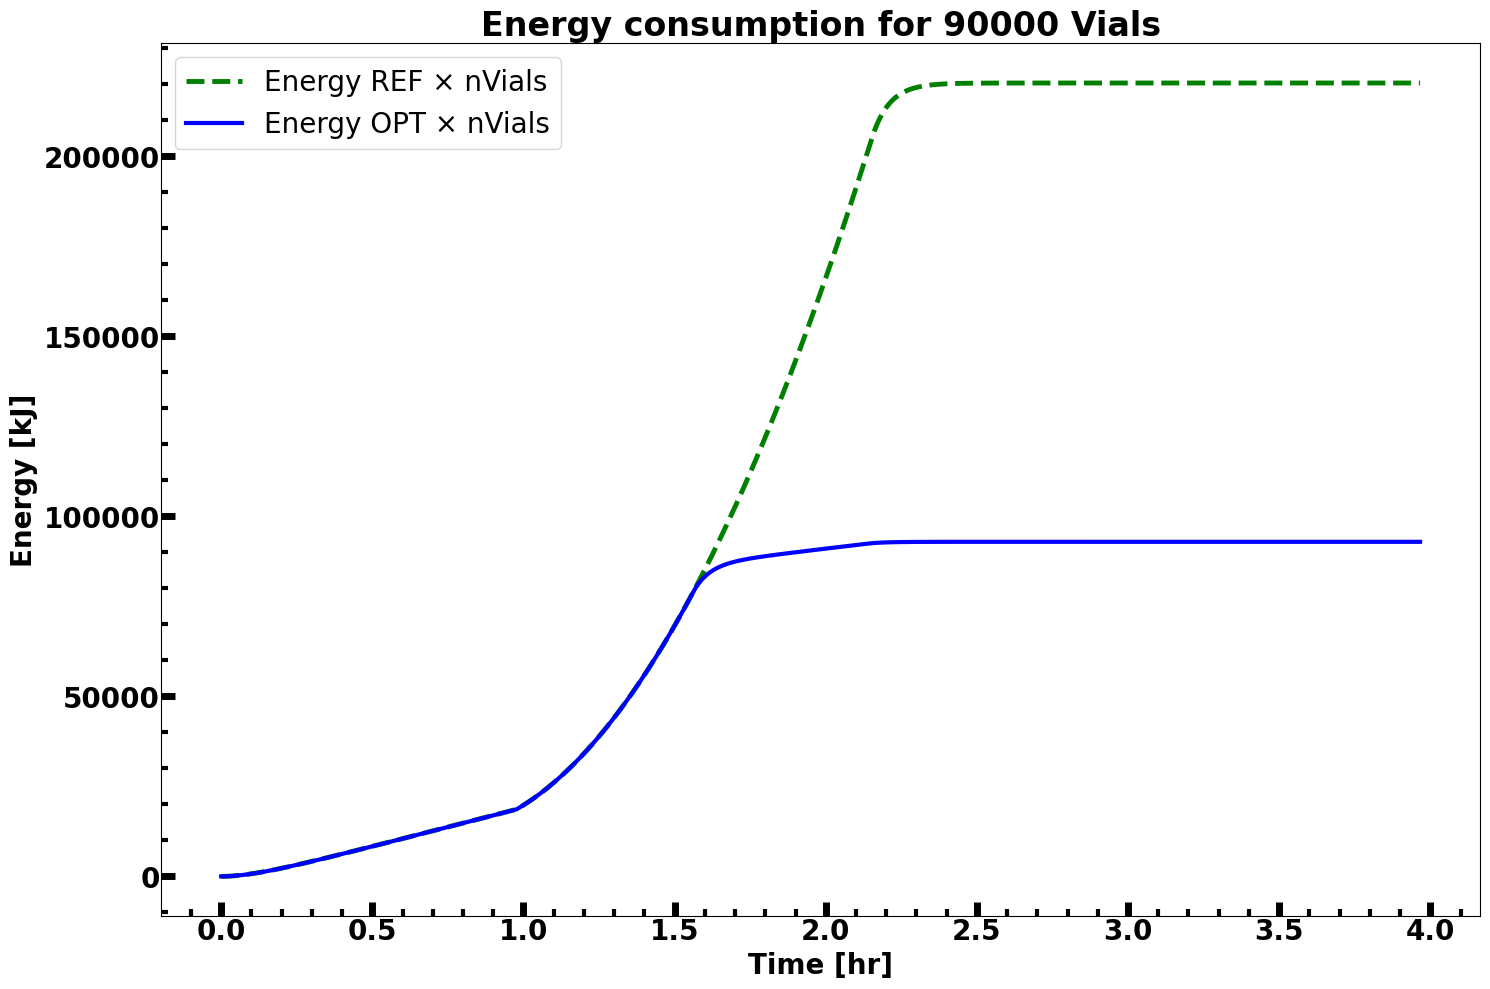

In [15]:
# REF-Daten
t_ref, q_ref, E_ref = ref.compute_power_and_energy(out_ref, vial, product, h_freezing)

# NEW-Daten (Energy-consistent)
t_new, q_new, E_new = ref.compute_power_and_energy(out_new, vial, product, h_freezing)

# Power ohne Skalierung
ref.plot_power_compare(t_ref, -q_ref, t_new, -q_new, scale=1, save_path="power_compare_original.pdf")

# Power ×90000
ref.plot_power_compare(t_ref, -q_ref, t_new, -q_new, scale=90000, save_path="power_compare_scaled.pdf")

# Energy ohne Skalierung
ref.plot_energy_compare(t_ref, -E_ref, t_new, -E_new, scale=1, save_path="energy_compare_original.pdf")

# Energy ×90000
ref.plot_energy_compare(t_ref, -E_ref, t_new, -E_new, scale=90000, save_path="energy_compare_scaled.pdf")

